In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Modelo y datos escalados de test
model = joblib.load('../models/xgboost_tuned.pkl')
X_test = pd.read_csv('../data/processed/X_test_tuned.csv')
y_test = pd.read_csv('../data/processed/y_test.csv')['Exited']

# Datos originales (sin escalar) del MISMO split de test
raw = pd.read_csv('../data/raw/Churn_Modelling.csv').drop(columns=['RowNumber', 'CustomerId', 'Surname'])
_, raw_test = train_test_split(raw, test_size=0.2, random_state=42, stratify=raw['Exited'])
raw_test = raw_test.reset_index(drop=True)

# Verificación: debe ser el mismo orden de clientes
assert (raw_test['Exited'].values == y_test.values).all(), "El split no coincide"
print("✅ Split verificado")
print(f"Clientes en test: {len(raw_test)}")
raw_test.head()

✅ Split verificado
Clientes en test: 2000


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,585,France,Male,36,7,0.00,2,1,0,94283.09,0
1,525,Germany,Male,33,4,131023.76,2,0,0,55072.93,0
2,557,Spain,Female,40,4,0.00,2,0,1,105433.53,0
3,639,Spain,Male,34,5,139393.19,2,0,0,33950.08,0
4,640,Spain,Female,34,3,77826.80,1,1,1,168544.85,0


In [2]:
df = raw_test.copy()
df['risk_score'] = model.predict_proba(X_test)[:, 1]

# Posición en el ranking (0 = más riesgoso, 1 = menos riesgoso)
df['risk_rank'] = df['risk_score'].rank(pct=True, ascending=False)

# Alto: top 20% | Medio: siguiente 30% | Bajo: 50% restante
df['segment'] = pd.cut(df['risk_rank'], bins=[0, 0.2, 0.5, 1.0],
                       labels=['Alto', 'Medio', 'Bajo'], include_lowest=True)

seg = df.groupby('segment', observed=True).agg(
    clientes=('Exited', 'size'),
    churners_reales=('Exited', 'sum'),
    tasa_churn_real=('Exited', 'mean'),
    score_promedio=('risk_score', 'mean')
)
seg['pct_del_churn_total'] = seg['churners_reales'] / df['Exited'].sum()
print(seg.round(3))

         clientes  churners_reales  tasa_churn_real  score_promedio  \
segment                                                               
Alto          400              256            0.640           0.825   
Medio         600              108            0.180           0.453   
Bajo         1000               43            0.043           0.153   

         pct_del_churn_total  
segment                       
Alto                   0.629  
Medio                  0.265  
Bajo                   0.106  


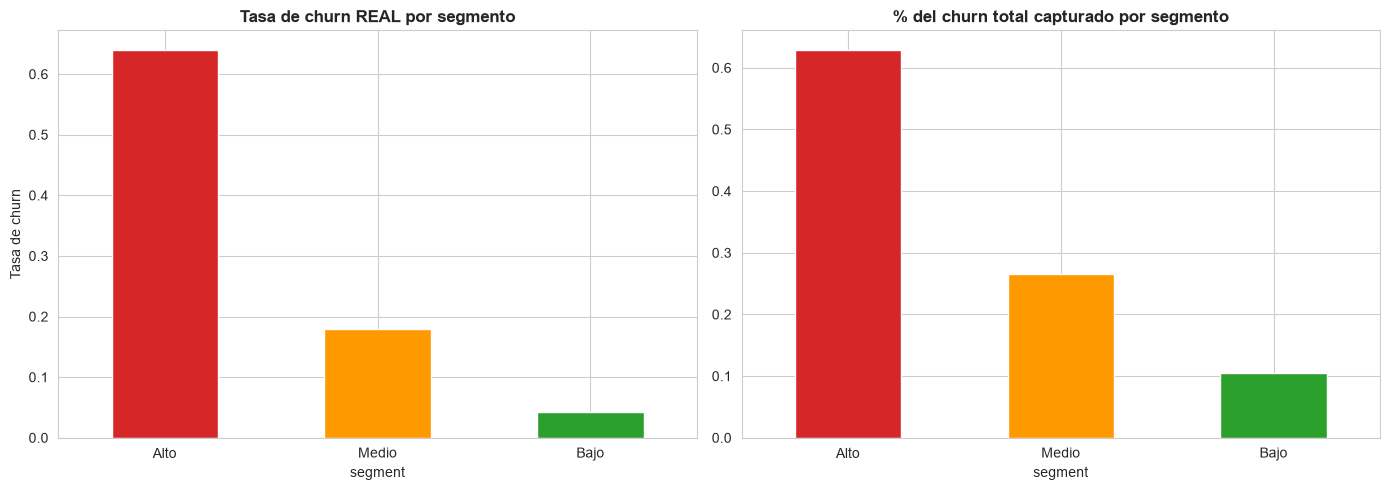

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = {'Alto': '#d62728', 'Medio': '#ff9900', 'Bajo': '#2ca02c'}
seg['tasa_churn_real'].plot(kind='bar', ax=axes[0], color=[colors[s] for s in seg.index])
axes[0].set_title('Tasa de churn REAL por segmento', fontweight='bold')
axes[0].set_ylabel('Tasa de churn')
axes[0].set_xticklabels(seg.index, rotation=0)

seg['pct_del_churn_total'].plot(kind='bar', ax=axes[1], color=[colors[s] for s in seg.index])
axes[1].set_title('% del churn total capturado por segmento', fontweight='bold')
axes[1].set_xticklabels(seg.index, rotation=0)

plt.tight_layout()
plt.show()

In [4]:
profile = df.groupby('segment', observed=True).agg(
    edad=('Age', 'mean'),
    balance=('Balance', 'mean'),
    productos=('NumOfProducts', 'mean'),
    pct_activos=('IsActiveMember', 'mean'),
    antiguedad=('Tenure', 'mean'),
    credit_score=('CreditScore', 'mean'),
    salario=('EstimatedSalary', 'mean')
)
print("PERFIL PROMEDIO POR SEGMENTO")
print(profile.round(2))

print("\nCHURN REAL POR PAÍS")
print(df.groupby('Geography')['Exited'].agg(['size', 'mean']).round(3))

print("\nCHURN REAL POR NÚMERO DE PRODUCTOS")
print(df.groupby('NumOfProducts')['Exited'].agg(['size', 'mean']).round(3))

PERFIL PROMEDIO POR SEGMENTO
          edad   balance  productos  pct_activos  antiguedad  credit_score  \
segment                                                                      
Alto     47.54  91948.15       1.46         0.32        4.78        643.09   
Medio    39.89  95859.65       1.29         0.49        4.95        645.52   
Bajo     34.70  59514.18       1.71         0.61        5.11        654.72   

           salario  
segment             
Alto     103511.56  
Medio    102429.54  
Bajo     100193.56  

CHURN REAL POR PAÍS
           size   mean
Geography             
France     1021  0.171
Germany     504  0.300
Spain       475  0.171

CHURN REAL POR NÚMERO DE PRODUCTOS
               size   mean
NumOfProducts             
1              1013  0.267
2               918  0.084
3                59  0.847
4                10  1.000


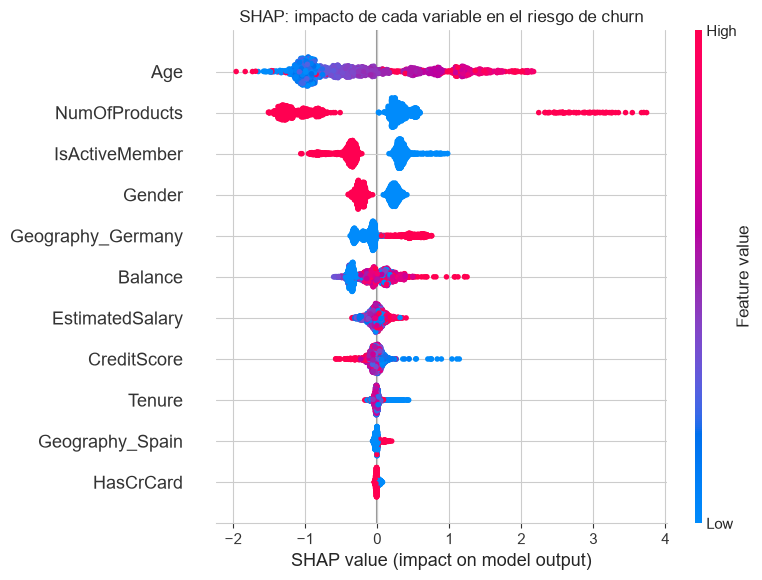

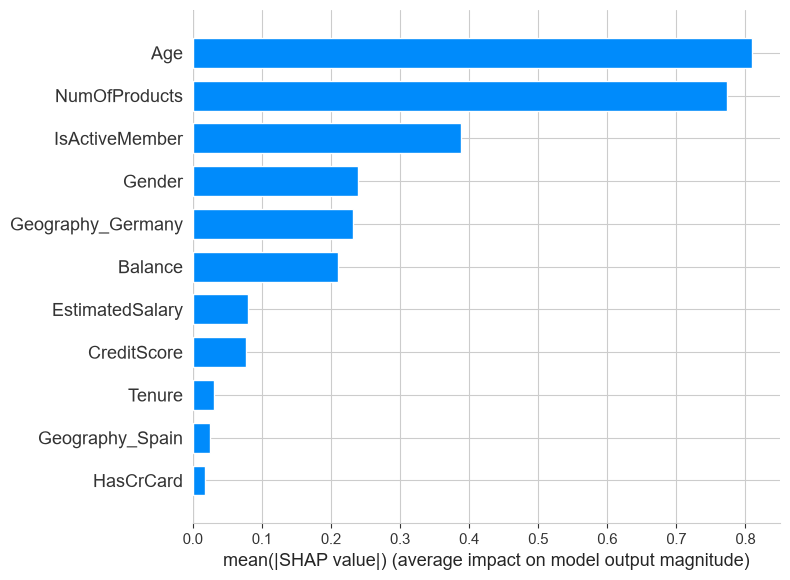

In [5]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

# Importancia global: cada punto es un cliente
shap.summary_plot(shap_values, X_test, show=False)
plt.title('SHAP: impacto de cada variable en el riesgo de churn')
plt.tight_layout()
plt.show()

# Versión resumida (barras)
shap.summary_plot(shap_values, X_test, plot_type='bar')

In [6]:
# SUPUESTOS (editables, ilustrativos)
valor_cliente = 1500    # margen anual que deja un cliente retenido (EUR)
costo_contacto = 50     # costo de la campaña por cliente contactado (EUR)
tasa_exito = 0.25       # % de churners contactados que logras retener

resultados = []
for pct in [0.10, 0.20, 0.30, 0.50, 1.00]:
    n = int(len(df) * pct)
    contactados = df.nlargest(n, 'risk_score')
    churners_alcanzados = contactados['Exited'].sum()
    retenidos = churners_alcanzados * tasa_exito
    beneficio = retenidos * valor_cliente
    costo = n * costo_contacto
    resultados.append({
        '% contactado': f'{pct:.0%}',
        'clientes contactados': n,
        'churners alcanzados': int(churners_alcanzados),
        'clientes retenidos': round(retenidos, 1),
        'beneficio (EUR)': round(beneficio),
        'costo (EUR)': costo,
        'neto (EUR)': round(beneficio - costo)
    })

roi_df = pd.DataFrame(resultados)
print(roi_df.to_string(index=False))

% contactado  clientes contactados  churners alcanzados  clientes retenidos  beneficio (EUR)  costo (EUR)  neto (EUR)
         10%                   200                  172                43.0            64500        10000       54500
         20%                   400                  256                64.0            96000        20000       76000
         30%                   600                  309                77.2           115875        30000       85875
         50%                  1000                  364                91.0           136500        50000       86500
        100%                  2000                  407               101.8           152625       100000       52625


In [7]:
df.drop(columns=['age_group'], errors='ignore').to_csv('../data/processed/customers_risk.csv', index=False)
print("✅ Guardado: ../data/processed/customers_risk.csv")
print(df['segment'].value_counts())

✅ Guardado: ../data/processed/customers_risk.csv
segment
Bajo     1000
Medio     600
Alto      400
Name: count, dtype: int64
